[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/eirasf/GCED-AA2/blob/main/es/lab6/lab6-parte2.ipynb)
# Práctica 6: Redes neuronales convolucionales - Complicando la CNN


### Pre-requisitos. Instalar paquetes
Usaremos las mismas librerías que para la parte 1. En esta ocasión utilizaremos la GPU, así que declaramos la variable `device`. Recuerda enviar tus modelos al device cuando los instancies (`m = MiModelo().to(device)`) y de enviar también los tensores de datos en el bucle de entrenamiento (`X_batch = X_batch.to(device)` y lo mismo para las etiquetas).

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.utils.data as data
import torchvision
from torchvision import transforms
import numpy as np
import random
import os
from matplotlib import pyplot as plt

# Semilla para reproducibilidad
seed = 1234567
torch.manual_seed(seed)
np.random.seed(seed)
random.seed(seed)
os.environ['PYTHONHASHSEED'] = str(seed)

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda:0


### Carga del conjunto de datos

En esta ocasión trabajaremos con el conjunto de imágenes *cifar10*, que son imágenes con tres canales.

100%|██████████| 170M/170M [1:01:19<00:00, 46.3kB/s]


torch.Size([128, 3, 32, 32])
torch.Size([128])


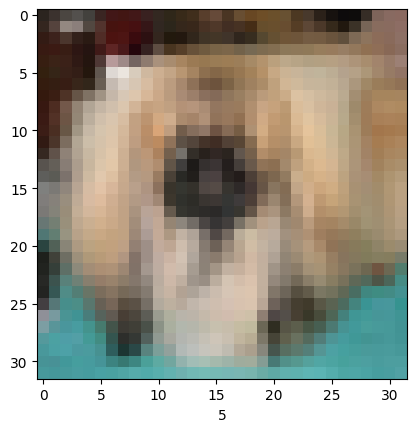

In [2]:
# Los datos de CIFAR se estandarizan utilizando su media y desviación típicas
cifar10_mean = (0.4914, 0.4822, 0.4465)
cifar10_std = (0.2023, 0.1994, 0.2010)

transform = transforms.Compose([
    transforms.ToTensor(),
    # Usamos transforms.Normalize para estandarizar con las medias y desviaciones dadas
    transforms.Normalize(mean=cifar10_mean, std=cifar10_std)
])

train_val = torchvision.datasets.CIFAR10(
    root="./data", train=True, download=True, transform=transform
)
test_set = torchvision.datasets.CIFAR10(
    root="./data", train=False, download=True, transform=transform
)

# Divide train_val en train y val (80/20) usando un generador con semilla
train_size = int(0.8 * len(train_val))
val_size = len(train_val) - train_size
generator = torch.Generator().manual_seed(seed)
train_set, val_set = data.random_split(train_val, [train_size, val_size], generator=generator)

# Crea los DataLoaders
batch_size = 128
train_loader = data.DataLoader(train_set, batch_size=batch_size, shuffle=True)
val_loader = data.DataLoader(val_set, batch_size=batch_size, shuffle=False)
test_loader = data.DataLoader(test_set, batch_size=batch_size, shuffle=False)

NUM_CLASSES = 10
IMAGE_SHAPE = (3, 32, 32)  # CIFAR-10 tiene 3 canales y tamaño 32x32

# Mostramos un ejemplo del conjunto
images, labels = next(iter(train_loader))
print(images.shape)  # [128, 3, 32, 32]
print(labels.shape)  # [128]

# Para mostrar los datos con pyplot hay que deshacer la normalización y poner los canales como última dimensión del tensor
def unnormalize(img):
    img = img.permute(1, 2, 0)  # CHW -> HWC
    img = img * torch.tensor(cifar10_std) + torch.tensor(cifar10_mean)
    return img.clamp(0, 1)

plt.imshow(unnormalize(images[0]))
plt.xlabel(labels[0].item())
plt.show()

## Creando el modelo y entrenando el modelo
Para este problema vamos a utilizar la siguiente arquitectura:
1. [Convolución 2D](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html) de 32 filtros y tamaño de kernel 3, con activación ReLU
1. [Pooling 2D](https://docs.pytorch.org/docs/2.8/generated/torch.nn.MaxPool2d.html) tomando el máximo de cada grupo de 2x2
1. [Convolución 2D](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html) de 64 filtros y tamaño de kernel 3, con activación ReLU
1. [Pooling 2D](https://docs.pytorch.org/docs/2.8/generated/torch.nn.MaxPool2d.html) tomando el máximo de cada grupo de 2x2
1. [Convolución 2D](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html) de 64 filtros y tamaño de kernel 3, con activación ReLU
1. Capa Densa (requiere aplanado previo) de 64 unidades y activación ReLU
1. Capa de salida

Define el modelo y haz el entrenamiento como en la anterior parte.

Entrenando el modelo CNN en CIFAR-10...
Epoch [1/16] | Train Loss: 1.3429, Train Acc: 51.64% | Val Loss: 1.3548, Val Acc: 51.37%
Epoch [2/16] | Train Loss: 1.1606, Train Acc: 58.80% | Val Loss: 1.2111, Val Acc: 56.89%
Epoch [3/16] | Train Loss: 0.9984, Train Acc: 64.78% | Val Loss: 1.0649, Val Acc: 61.77%
Epoch [4/16] | Train Loss: 0.9027, Train Acc: 68.32% | Val Loss: 0.9959, Val Acc: 65.28%
Epoch [5/16] | Train Loss: 0.7935, Train Acc: 72.50% | Val Loss: 0.9106, Val Acc: 68.64%
Epoch [6/16] | Train Loss: 0.7309, Train Acc: 74.72% | Val Loss: 0.8793, Val Acc: 69.22%
Epoch [7/16] | Train Loss: 0.7087, Train Acc: 75.31% | Val Loss: 0.8743, Val Acc: 69.86%
Epoch [8/16] | Train Loss: 0.6360, Train Acc: 78.26% | Val Loss: 0.8514, Val Acc: 71.03%
Epoch [9/16] | Train Loss: 0.5965, Train Acc: 79.36% | Val Loss: 0.8324, Val Acc: 71.07%
Epoch [10/16] | Train Loss: 0.5666, Train Acc: 80.62% | Val Loss: 0.8503, Val Acc: 70.86%
Epoch [11/16] | Train Loss: 0.5181, Train Acc: 82.08% | Val Loss: 0.8

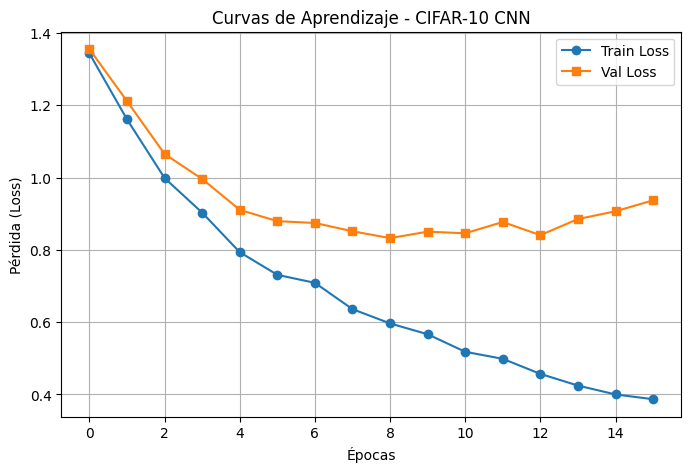

In [3]:
# --- 1. Definición de la Red Convolucional para CIFAR-10 ---
class CIFARCNN(nn.Module):
    def __init__(self):
        super(CIFARCNN, self).__init__()
        self.features = nn.Sequential(
            # 1. Convolución 2D (32 filtros, kernel 3) + ReLU + MaxPool 2x2
            nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # 3. Convolución 2D (64 filtros, kernel 3) + ReLU + MaxPool 2x2
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # 5. Convolución 2D (64 filtros, kernel 3) + ReLU
            nn.Conv2d(in_channels=64, out_channels=64, kernel_size=3),
            nn.ReLU()
        )

        # 6. Aplanado + Capa Densa (64 unidades) + ReLU + 7. Capa de salida
        # Con entradas de 32x32, tras las capas anteriores las dimensiones espaciales resultantes son 4x4 con 64 canales (64 * 4 * 4 = 1024)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 64),
            nn.ReLU(),
            nn.Linear(64, NUM_CLASSES)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

# --- 2. Funciones de Evaluación y Entrenamiento ---
def evaluate(model, dataloader, loss_fn, device):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, targets in dataloader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            loss = loss_fn(outputs, targets)
            total_loss += loss.item() * inputs.size(0)

            _, predicted = torch.max(outputs, 1)
            correct += (predicted == targets).sum().item()
            total += targets.size(0)

    return total_loss / total, correct / total

def train_model(model, train_loader, val_loader, loss_fn, optimizer, device, num_epochs=16):
    train_losses = []
    val_losses = []

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0

        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device), targets.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = loss_fn(outputs, targets)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)

        train_loss, train_acc = evaluate(model, train_loader, loss_fn, device)
        val_loss, val_acc = evaluate(model, val_loader, loss_fn, device)

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        print(f"Epoch [{epoch+1}/{num_epochs}] "
              f"| Train Loss: {train_loss:.4f}, Train Acc: {train_acc*100:.2f}% "
              f"| Val Loss: {val_loss:.4f}, Val Acc: {val_acc*100:.2f}%")

    return train_losses, val_losses

# --- 3. Instanciación del Modelo, Pérdida y Optimizador ---
model = CIFARCNN().to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# --- 4. Ejecución del Entrenamiento ---
print("Entrenando el modelo CNN en CIFAR-10...")
train_losses, val_losses = train_model(
    model, train_loader, val_loader, loss_fn, optimizer, device, num_epochs=16
)

# --- 5. Rendimiento en Test y Curvas de Aprendizaje ---
test_loss, test_acc = evaluate(model, test_loader, loss_fn, device)
print(f"\nResultados en el conjunto de Test -> Pérdida: {test_loss:.4f} | Precisión: {test_acc*100:.2f}%")

# Gráfica de curvas de entrenamiento y validación
plt.figure(figsize=(8, 5))
plt.plot(train_losses, label='Train Loss', marker='o')
plt.plot(val_losses, label='Val Loss', marker='s')
plt.title('Curvas de Aprendizaje - CIFAR-10 CNN')
plt.xlabel('Épocas')
plt.ylabel('Pérdida (Loss)')
plt.legend()
plt.grid(True)
plt.show()

Si todo ha ido bien, deberías haber obtenido una preción en test de al menos un 60%, lo cual no es desdeñable para una red sencilla.

## Mejora del rendimiento
Vuelve sobre la arquitectura del modelo e incluye capas de [BatchNorm2d](https://docs.pytorch.org/docs/stable/generated/torch.nn.BatchNorm2d.html) después de cada capa convolucional. Esto hará que las salidas de esa capa se estandaricen para que sigan una distribución N(0,1) (la operación de estandarización se incluye en el grafo y, por tanto, el cómputo de los gradientes). El efecto de esta capa es que se evitará que el gradiente del lote tenga una gran componente solo dedicada a acercar las salidas a la media/desviación de las muestras en cada capa. En consecuencia, el aprendizaje se acelera.

### Ejercicios
 - Repite el entrenamiento con la nueva arquitectura. ¿Qué efecto has notado? ¿Puedes mejorar el rendimiento en test utilizando conceptos vistos en Laboratorios anteriores?
 - Prueba distintas arquitecturas e intenta mejorar el rendimiento en test.

Entrenando la red CNN con Batch Normalization...
Epoch [1/16] | Train Loss: 0.9856, Train Acc: 64.98% | Val Loss: 1.0484, Val Acc: 62.41%
Epoch [2/16] | Train Loss: 0.7895, Train Acc: 72.91% | Val Loss: 0.9008, Val Acc: 68.59%
Epoch [3/16] | Train Loss: 0.8616, Train Acc: 70.15% | Val Loss: 1.0184, Val Acc: 65.40%
Epoch [4/16] | Train Loss: 0.6760, Train Acc: 76.47% | Val Loss: 0.8768, Val Acc: 70.41%
Epoch [5/16] | Train Loss: 0.5930, Train Acc: 79.25% | Val Loss: 0.8381, Val Acc: 71.55%
Epoch [6/16] | Train Loss: 0.5392, Train Acc: 81.19% | Val Loss: 0.8543, Val Acc: 71.34%
Epoch [7/16] | Train Loss: 0.4419, Train Acc: 84.71% | Val Loss: 0.8053, Val Acc: 72.94%
Epoch [8/16] | Train Loss: 0.4006, Train Acc: 86.36% | Val Loss: 0.8326, Val Acc: 73.20%
Epoch [9/16] | Train Loss: 0.4739, Train Acc: 82.52% | Val Loss: 0.9934, Val Acc: 70.37%
Epoch [10/16] | Train Loss: 0.3943, Train Acc: 85.84% | Val Loss: 0.9403, Val Acc: 72.19%
Epoch [11/16] | Train Loss: 0.2815, Train Acc: 90.37% | Val 

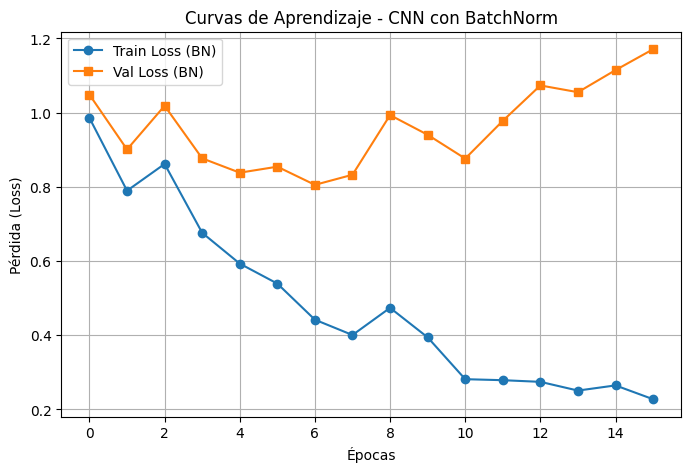

In [5]:
# --- 1. Definición del Nuevo Modelo con BatchNorm2d ---
class CIFARCNNBatchNorm(nn.Module):
    def __init__(self):
        super(CIFARCNNBatchNorm, self).__init__()
        self.features = nn.Sequential(
            # 1. Conv2d + BatchNorm2d + ReLU + MaxPool 2x2
            nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # 3. Conv2d + BatchNorm2d + ReLU + MaxPool 2x2
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # 5. Conv2d + BatchNorm2d + ReLU
            nn.Conv2d(in_channels=64, out_channels=64, kernel_size=3),
            nn.BatchNorm2d(64),
            nn.ReLU()
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 64),
            nn.ReLU(),
            nn.Linear(64, NUM_CLASSES)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

# --- 2. Funciones de Aprendizaje y Evaluación ---
def evaluate(model, dataloader, loss_fn, device):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, targets in dataloader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            loss = loss_fn(outputs, targets)
            total_loss += loss.item() * inputs.size(0)

            _, predicted = torch.max(outputs, 1)
            correct += (predicted == targets).sum().item()
            total += targets.size(0)

    return total_loss / total, correct / total

def train_model(model, train_loader, val_loader, loss_fn, optimizer, device, num_epochs=16):
    train_losses = []
    val_losses = []

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0

        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device), targets.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = loss_fn(outputs, targets)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)

        train_loss, train_acc = evaluate(model, train_loader, loss_fn, device)
        val_loss, val_acc = evaluate(model, val_loader, loss_fn, device)

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        print(f"Epoch [{epoch+1}/{num_epochs}] "
              f"| Train Loss: {train_loss:.4f}, Train Acc: {train_acc*100:.2f}% "
              f"| Val Loss: {val_loss:.4f}, Val Acc: {val_acc*100:.2f}%")

    return train_losses, val_losses

# --- 3. Instanciación y Entrenamiento ---
model_bn = CIFARCNNBatchNorm().to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_bn.parameters(), lr=0.001)

print("Entrenando la red CNN con Batch Normalization...")
train_losses, val_losses = train_model(
    model_bn, train_loader, val_loader, loss_fn, optimizer, device, num_epochs=16
)

# --- 4. Examen de Curvas y Rendimiento en Test ---
test_loss, test_acc = evaluate(model_bn, test_loader, loss_fn, device)
print(f"\nResultados en Test (con BatchNorm) -> Pérdida: {test_loss:.4f} | Precisión: {test_acc*100:.2f}%")

plt.figure(figsize=(8, 5))
plt.plot(train_losses, label='Train Loss (BN)', marker='o')
plt.plot(val_losses, label='Val Loss (BN)', marker='s')
plt.title('Curvas de Aprendizaje - CNN con BatchNorm')
plt.xlabel('Épocas')
plt.ylabel('Pérdida (Loss)')
plt.legend()
plt.grid(True)
plt.show()